# Mobile Product Segmentation & Recommendation System
Global Mobile Reviews dataset (50,000 reviews · 7 brands · 22 models · 8 countries) - end-to-end walk-through.

All logic lives in the `src/` package, so this notebook, `run_pipeline.py` and the Streamlit app share exactly the same code.

In [1]:
import sys, json, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, joblib
from IPython.display import Image, display
from src import config as C, preprocessing, features, segmentation, recommender, eda
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
show = lambda f: display(Image(str(C.FIGURES_DIR / f)))

## 1. Data collection - CSV ➜ DataFrame

In [2]:
raw = preprocessing.load_raw()
print(raw.shape)
raw.head()

(50000, 22)


,review_id,customer_name,age,brand,model,price_usd,price_local,currency,exchange_rate_to_usd,rating,sentiment,country,language,review_date,verified_purchase,battery_life_rating,camera_rating,performance_rating,design_rating,display_rating,helpful_votes,source
0,1,Aryan Maharaj,45,Realme,Realme 12 Pro,337.31,₹27996.73,INR,83.00,2.0,Negative,India,Hindi,11/6/2023,True,1,1,3,2,1,1,Amazon
1,2,Davi Miguel Sousa,18,Realme,Realme 12 Pro,307.78,R$1754.35,BRL,5.70,4.0,Positive,Brazil,Portuguese,3/30/2023,True,3,2,4,3,2,5,Flipkart
2,3,Pahal Balay,27,Google,Pixel 6,864.53,₹71755.99,INR,83.00,4.0,Positive,India,Hindi,12/7/2022,True,3,5,3,2,4,8,AliExpress
3,4,David Guzman,19,Xiaomi,Redmi Note 13,660.94,د.إ2425.65,AED,3.67,3.0,Positive,UAE,English,3/11/2025,False,1,3,2,1,2,3,Amazon
4,5,Yago Leão,38,Motorola,Edge 50,792.13,R$4515.14,BRL,5.70,3.0,Neutral,Brazil,Portuguese,9/29/2023,True,3,3,2,2,1,0,BestBuy


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   review_id             50000 non-null  int64  
 1   customer_name         50000 non-null  str    
 2   age                   50000 non-null  int64  
 3   brand                 50000 non-null  str    
 4   model                 50000 non-null  str    
 5   price_usd             47550 non-null  float64
 6   price_local           47569 non-null  str    
 7   currency              50000 non-null  str    
 8   exchange_rate_to_usd  50000 non-null  float64
 9   rating                47547 non-null  float64
 10  sentiment             47555 non-null  str    
 11  country               50000 non-null  str    
 12  language              50000 non-null  str    
 13  review_date           50000 non-null  str    
 14  verified_purchase     50000 non-null  bool   
 15  battery_life_rating   50000 no

In [4]:
nulls = raw.isna().sum().to_frame('nulls')
nulls['%'] = (nulls.nulls / len(raw) * 100).round(2)
nulls[nulls.nulls > 0].T

,price_usd,price_local,rating,sentiment,source
nulls,2450.0,2431.00,2453.00,2445.00,2448.0
%,4.9,4.86,4.91,4.89,4.9


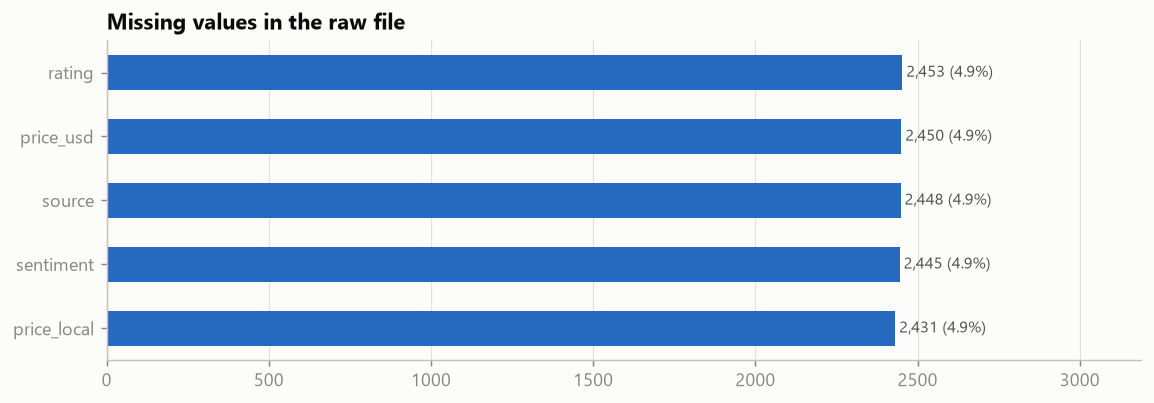

In [5]:
show('eda_00_missing_values.png')

### Discovering the data's structure
* **price_local = price_usd × exchange_rate_to_usd** holds on 100% of complete rows → a missing price is recovered exactly from the other price.
* `price_local` is text with a currency symbol (`₹27996.73`, `$1,010.68 `) → parsed to a number.
* `rating` follows the mean of the five aspect ratings, and `sentiment` follows `rating`.

In [6]:
sym, val = preprocessing.parse_local_price(raw.price_local)
ok = raw.price_usd.notna() & val.notna()
err = (val[ok] - raw.price_usd[ok] * raw.exchange_rate_to_usd[ok]).abs()
print('identity holds:', (err < 0.01).mean(), '| max error:', err.max())
pd.crosstab(raw.rating, raw.sentiment)

identity holds: 1.0 | max error: 0.005000000000109139


sentiment,Negative,Neutral,Positive
rating,,,
1.0,4461,1242,25
2.0,3467,4612,754
3.0,880,4301,6094
4.0,54,1118,11531
5.0,0,76,6614


## 2. Data cleaning & preprocessing
1. Text standardisation, duplicate removal (exact rows, repeated `review_id`, same content under a new id)
2. Type conversion: dates, booleans, integers; `price_local` parsed to `price_local_value`
3. Validation: brand↔model and country↔currency mappings, rating ranges, age range, price identity
4. Prices: exact recovery via the identity; 123 rows with both prices missing → model median
5. `rating` → most frequent rating among reviews with the same aspect average and sentiment; `sentiment` → most frequent sentiment for the same rating and aspect average (accuracy measured on held-out rows)
6. `source` → `Unknown` (it has no relationship with any other column)

In [7]:
clean, log = preprocessing.clean(raw)
for k, v in log.items():
    if k != 'raw_nulls': print(f'{k:<36} {v}')

raw_shape                            [50000, 22]
duplicates_removed                   0
unparseable_dates                    0
brand_model_conflicts                0
country_currency_conflicts           0
out_of_range_ratings                 0
invalid_age                          0
price_identity_holds_share           1.0
price_identity_violations_fixed      0
price_usd_recovered_exactly          2327
price_local_recovered_exactly        2308
price_both_missing_model_median      123
imputation_check                     {'rating_rule_accuracy': 0.7776, 'rating_rule_within_1_star': 0.9997, 'rating_global_mode_accuracy': 0.2806, 'sentiment_rule_accuracy': 0.7445, 'sentiment_global_mode_accuracy': 0.5606}
rating_imputed                       2453
sentiment_imputed                    2445
source_filled_unknown                2448
rows_dropped_unrecoverable           0
remaining_nulls                      0
clean_shape                          [50000, 26]


In [8]:
print('Remaining nulls:', clean.isna().sum().sum(), '| duplicates:', clean.duplicated().sum())
clean.dtypes.to_frame('dtype').T

Remaining nulls: 0 | duplicates: 0


,review_id,customer_name,age,brand,model,price_usd,price_local,currency,exchange_rate_to_usd,rating,sentiment,country,language,review_date,verified_purchase,battery_life_rating,camera_rating,performance_rating,design_rating,display_rating,helpful_votes,source,price_local_value,price_imputed,rating_imputed,sentiment_imputed
dtype,int64,str,int64,str,str,float64,str,str,float64,int64,str,str,str,datetime64[us],bool,int64,int64,int64,int64,int64,int64,str,float64,bool,bool,bool


## 3. Feature engineering & encoding
* `aspect_avg` (mean of 5 aspect ratings), `rating_gap`, `sentiment_score` (-1/0/1), `is_positive`
* `engagement_score` = helpful votes × 1.5 if verified purchase
* `value_score` = rating per $100 paid (price vs performance)
* `price_band`, `age_group`, review year / month
* Encoding: label codes for brand / model / country / source and one-hot brand + country
* Scaling: `StandardScaler` inside each K-Means pipeline

In [9]:
feat = features.add_features(clean)
enc = features.encode_categoricals(feat)
print(enc.shape)
enc[['brand','model','country','brand_code','model_code','country_code','brand_Apple','country_India','aspect_avg','engagement_score','value_score','price_band']].head()

(50000, 55)


,brand,model,country,brand_code,model_code,country_code,brand_Apple,country_India,aspect_avg,engagement_score,value_score,price_band
0,Realme,Realme 12 Pro,India,4,15,4,0,1,1.6,1.5,0.593,Budget (<$400)
1,Realme,Realme 12 Pro,Brazil,4,15,1,0,0,2.8,7.5,1.300,Budget (<$400)
2,Google,Pixel 6,India,1,10,4,0,1,3.4,12.0,0.463,Upper-mid ($700-1000)
3,Xiaomi,Redmi Note 13,UAE,6,17,5,0,0,1.8,3.0,0.454,Mid-range ($400-700)
4,Motorola,Edge 50,Brazil,2,0,1,0,0,2.2,0.0,0.379,Upper-mid ($700-1000)


In [10]:
products = features.product_catalog(feat)
products.head()

,model,brand,n_reviews,avg_price_usd,median_price_usd,min_price_usd,max_price_usd,avg_rating,positive_share,negative_share,avg_battery_life_rating,avg_camera_rating,avg_performance_rating,avg_design_rating,avg_display_rating,avg_aspect,avg_value_score,avg_engagement,verified_share,avg_age,top_country,bayes_rating,popularity_rank
0,Edge 50,Motorola,2315,508.6976,512.68,214.3740,789.7068,3.0868,0.5456,0.1909,2.6747,2.7015,2.7045,2.6886,2.7076,2.6954,0.6940,5.0890,0.8030,30.1793,Canada,3.0929,14
1,Galaxy A55,Samsung,1788,904.5384,901.34,420.4444,1375.1830,3.0895,0.5531,0.2041,2.7215,2.6762,2.6616,2.6941,2.6510,2.6809,0.3839,5.1518,0.8070,30.2332,Germany,3.0963,18
2,Galaxy Note 20,Samsung,1789,899.7462,905.24,420.5460,1377.9928,3.1487,0.5590,0.1878,2.7406,2.7295,2.7568,2.7473,2.7255,2.7400,0.3933,5.1635,0.8038,30.0945,India,3.1426,17
3,Galaxy S24,Samsung,1761,894.1257,890.57,420.1780,1376.5480,3.0710,0.5451,0.1959,2.6780,2.6638,2.6502,2.6763,2.6706,2.6678,0.3857,5.0369,0.7927,30.1607,Brazil,3.0820,21
4,Galaxy Z Flip,Samsung,1714,899.3834,906.84,423.0200,1382.1170,3.1354,0.5607,0.1896,2.7258,2.7392,2.7503,2.6931,2.7421,2.7301,0.3937,5.0718,0.7981,30.3646,Canada,3.1321,22


## 4. Exploratory data analysis

In [11]:
tables = eda.run_eda(feat, products)
tables['brand_summary']

,reviews,models,avg_price_usd,min_price_usd,max_price_usd,avg_rating,positive_share,avg_helpful,avg_value_score
brand,,,,,,,,,
Apple,7144,4,1103.555,700.01,1499.89,3.127,0.560,3.645,0.297
Samsung,7052,4,899.470,400.71,1399.70,3.111,0.554,3.645,0.389
Google,7234,3,804.592,500.05,1099.98,3.122,0.559,3.637,0.407
OnePlus,7136,3,672.705,350.01,999.90,3.128,0.560,3.669,0.506
Motorola,7061,3,506.472,200.01,799.99,3.111,0.549,3.637,0.707
Xiaomi,7241,3,449.645,200.14,699.96,3.110,0.555,3.612,0.778
Realme,7132,2,393.297,180.02,599.94,3.137,0.564,3.665,0.892


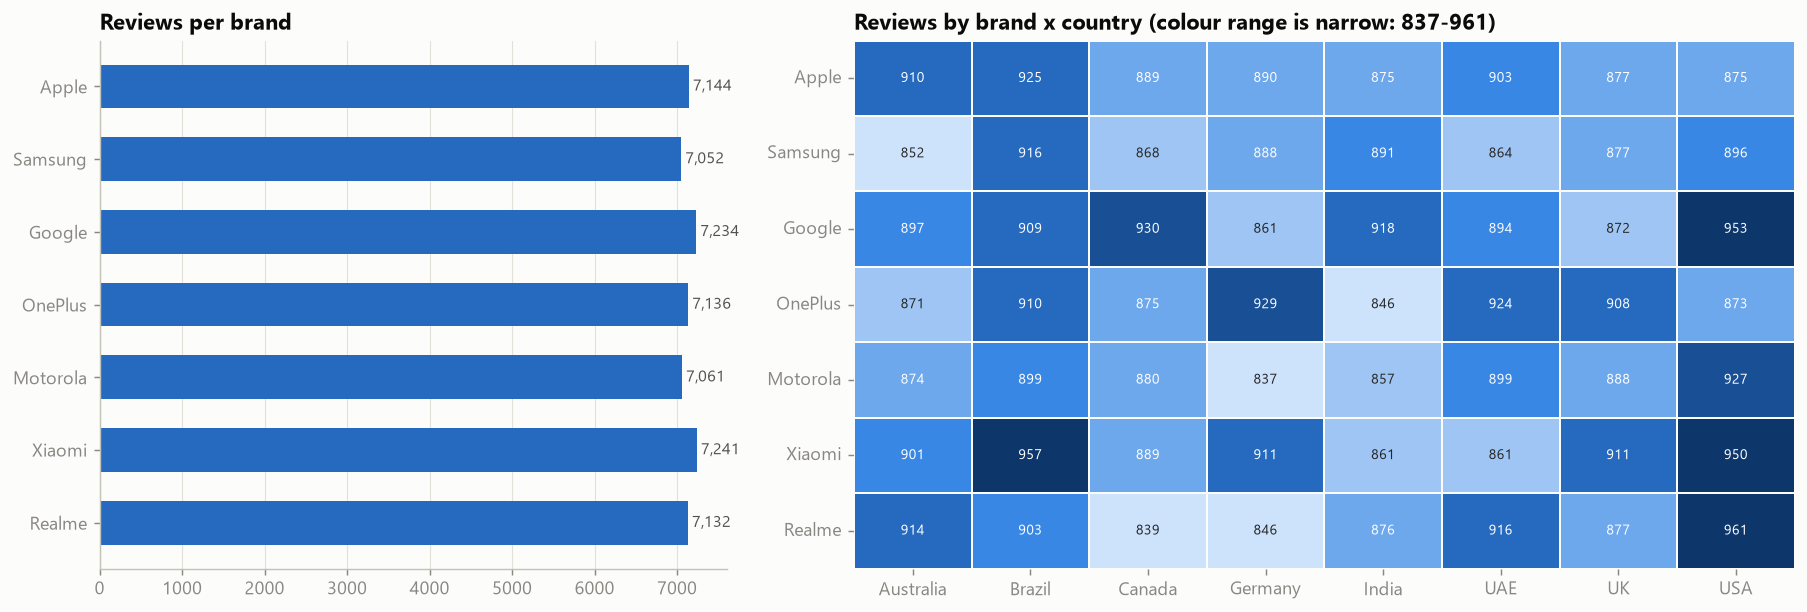

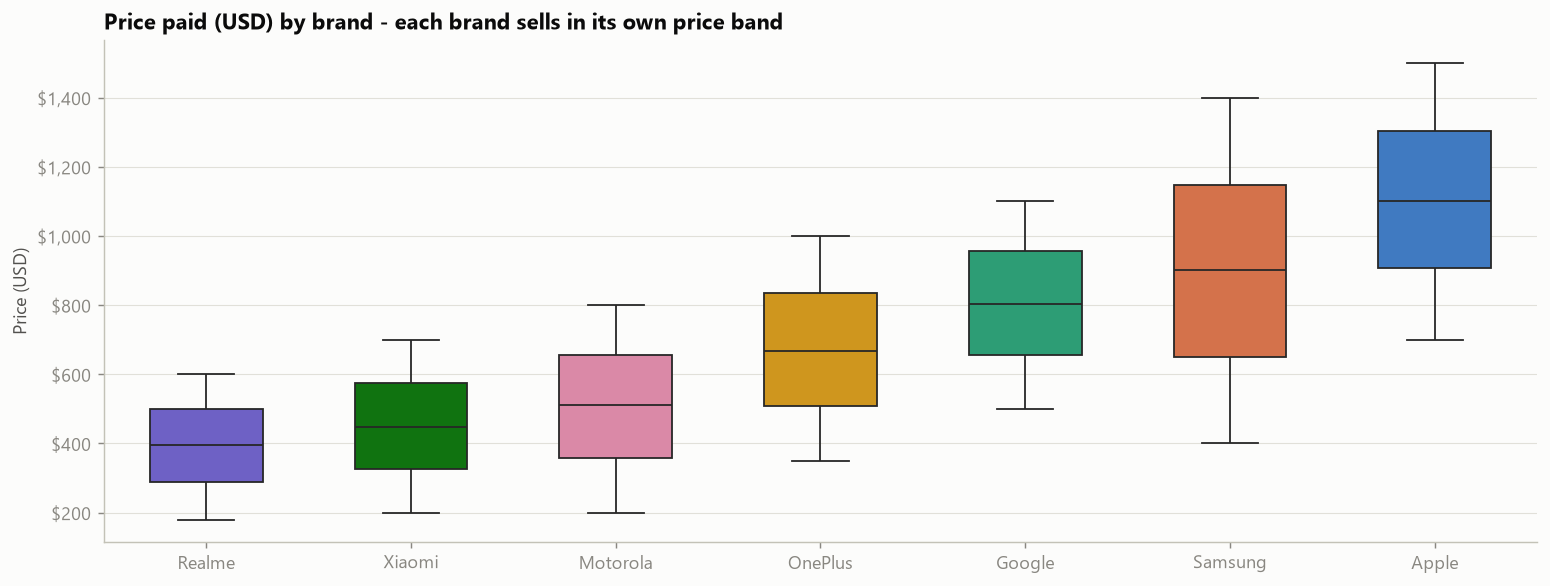

In [12]:
show('eda_01_brand_country_distribution.png'); show('eda_02_price_by_brand.png')

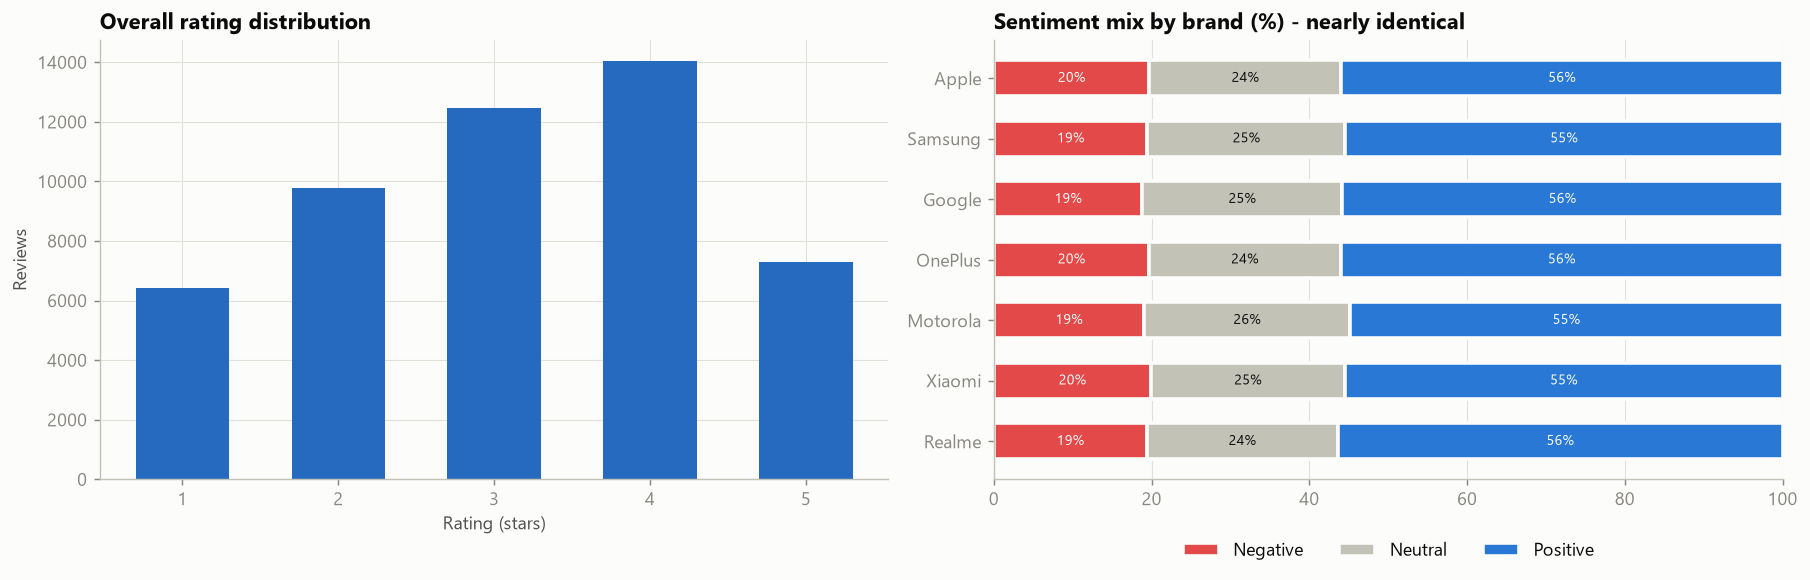

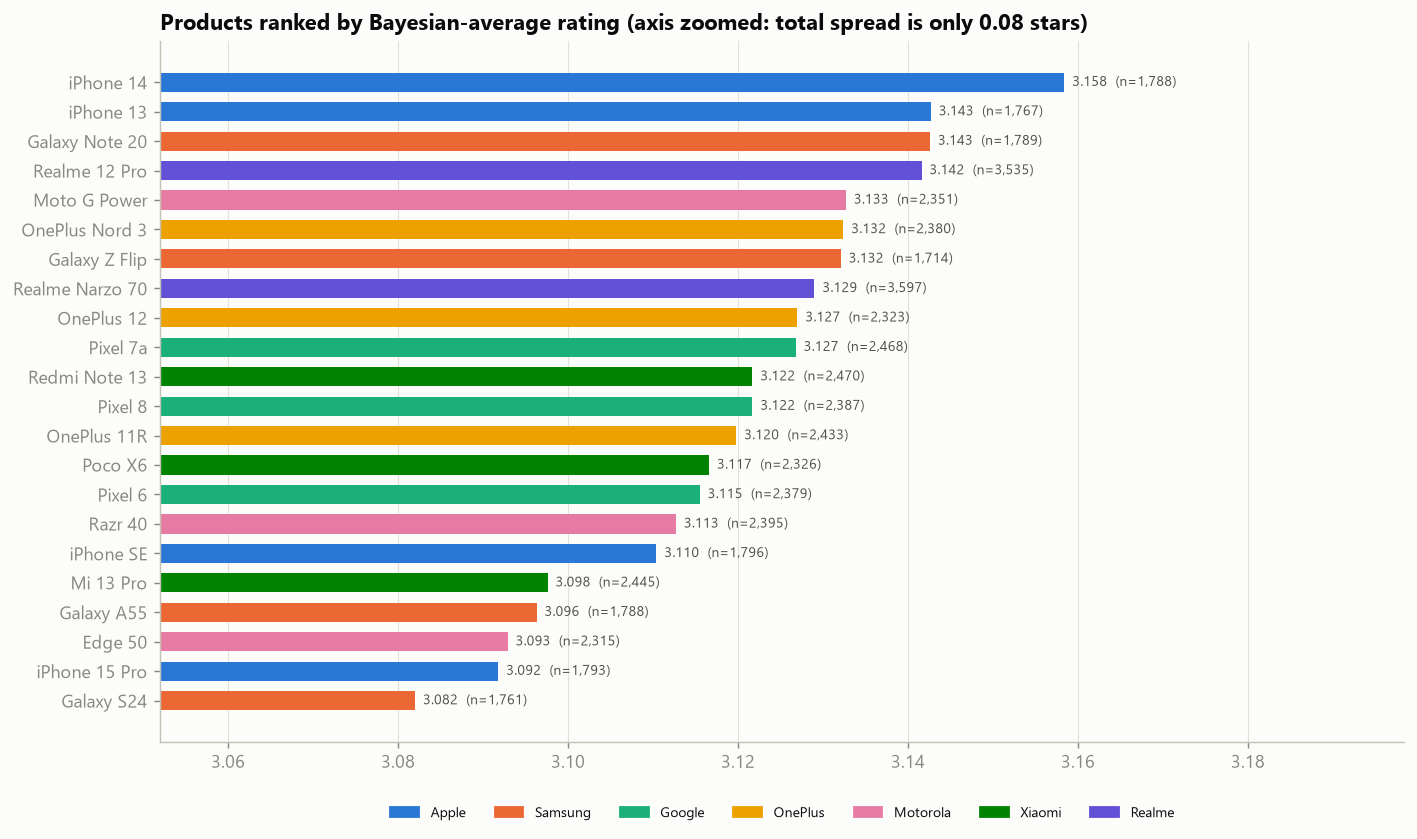

In [13]:
show('eda_03_rating_sentiment.png'); show('eda_04_top_low_products.png')

In [14]:
display(tables['top5_products']); display(tables['bottom5_products'])

,brand,n_reviews,avg_price_usd,avg_rating,bayes_rating,positive_share,negative_share
model,,,,,,,
iPhone 14,Apple,1788,1099.2199,3.1689,3.1584,0.5783,0.1935
iPhone 13,Apple,1767,1108.2654,3.1488,3.1427,0.5739,0.1879
Galaxy Note 20,Samsung,1789,899.7462,3.1487,3.1426,0.5590,0.1878
Realme 12 Pro,Realme,3535,393.8978,3.1446,3.1416,0.5717,0.1867
Moto G Power,Motorola,2351,504.6061,3.1353,3.1327,0.5636,0.1816


,brand,n_reviews,avg_price_usd,avg_rating,bayes_rating,positive_share,negative_share
model,,,,,,,
Mi 13 Pro,Xiaomi,2445,448.9141,3.0928,3.0976,0.5562,0.1996
Galaxy A55,Samsung,1788,904.5384,3.0895,3.0963,0.5531,0.2041
Edge 50,Motorola,2315,508.6976,3.0868,3.0929,0.5456,0.1909
iPhone 15 Pro,Apple,1793,1103.4099,3.0837,3.0918,0.5376,0.2103
Galaxy S24,Samsung,1761,894.1257,3.0710,3.0820,0.5451,0.1959


### Price vs ratings vs specifications

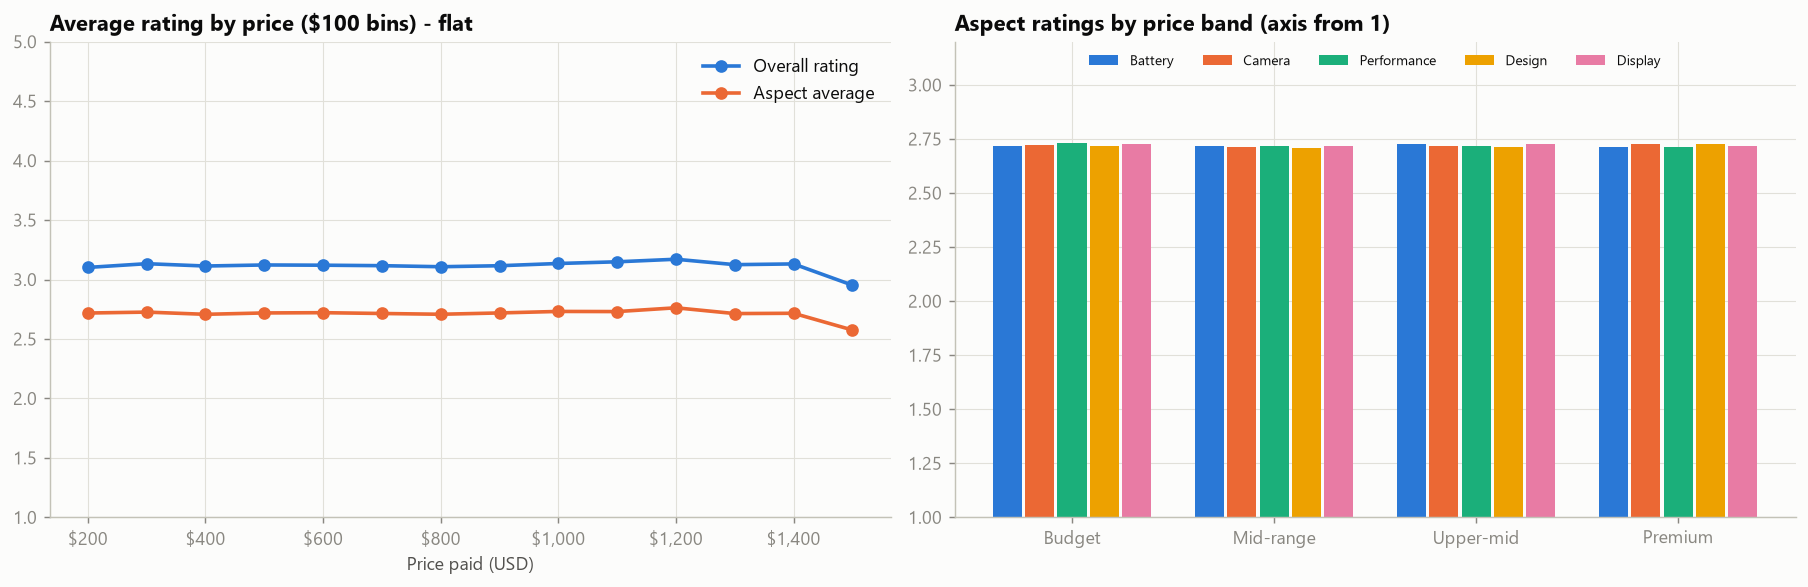

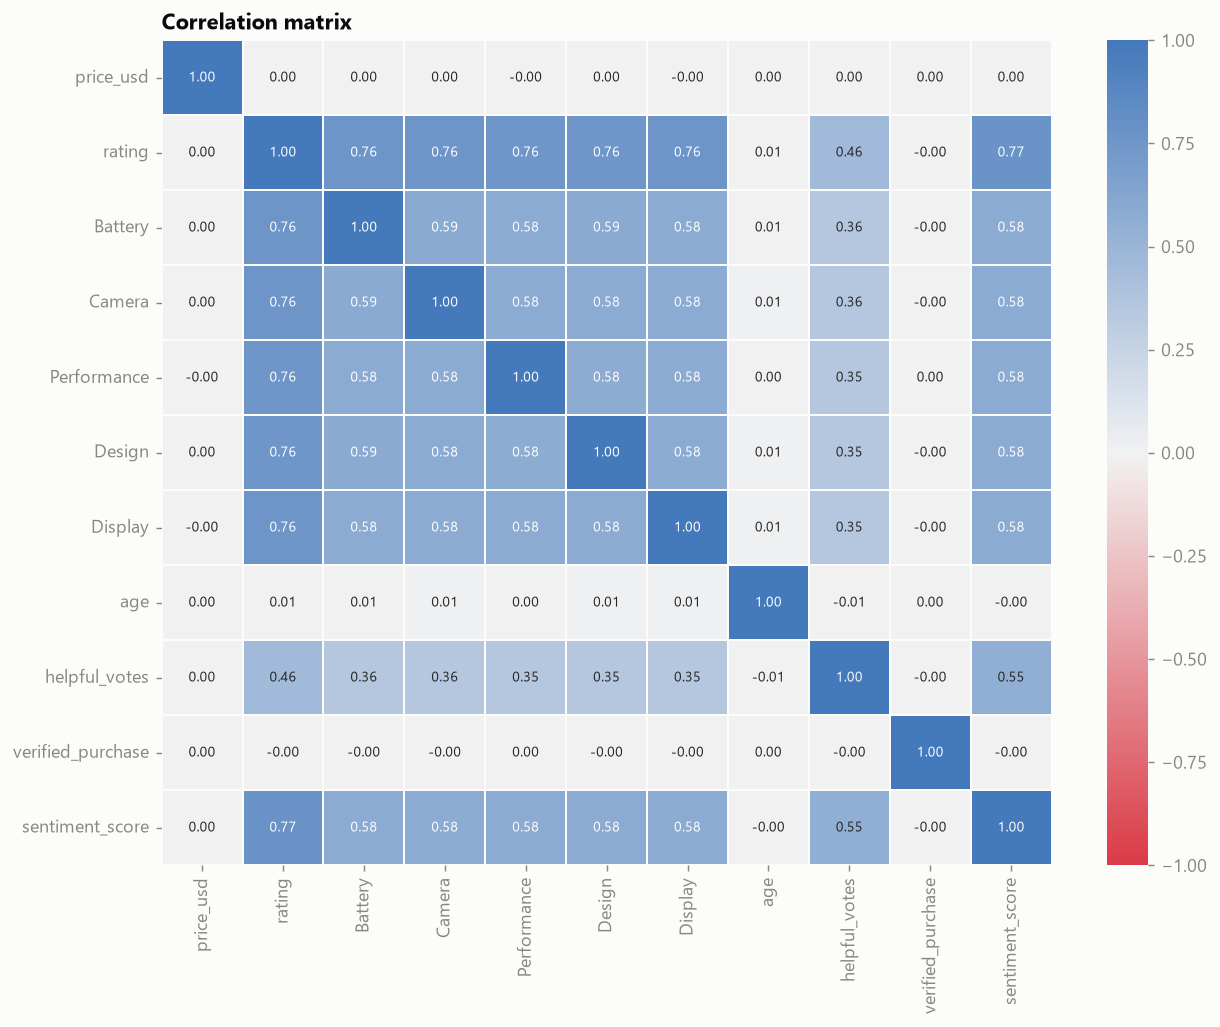

In [15]:
show('eda_05_price_vs_rating.png'); show('eda_06_correlation.png')

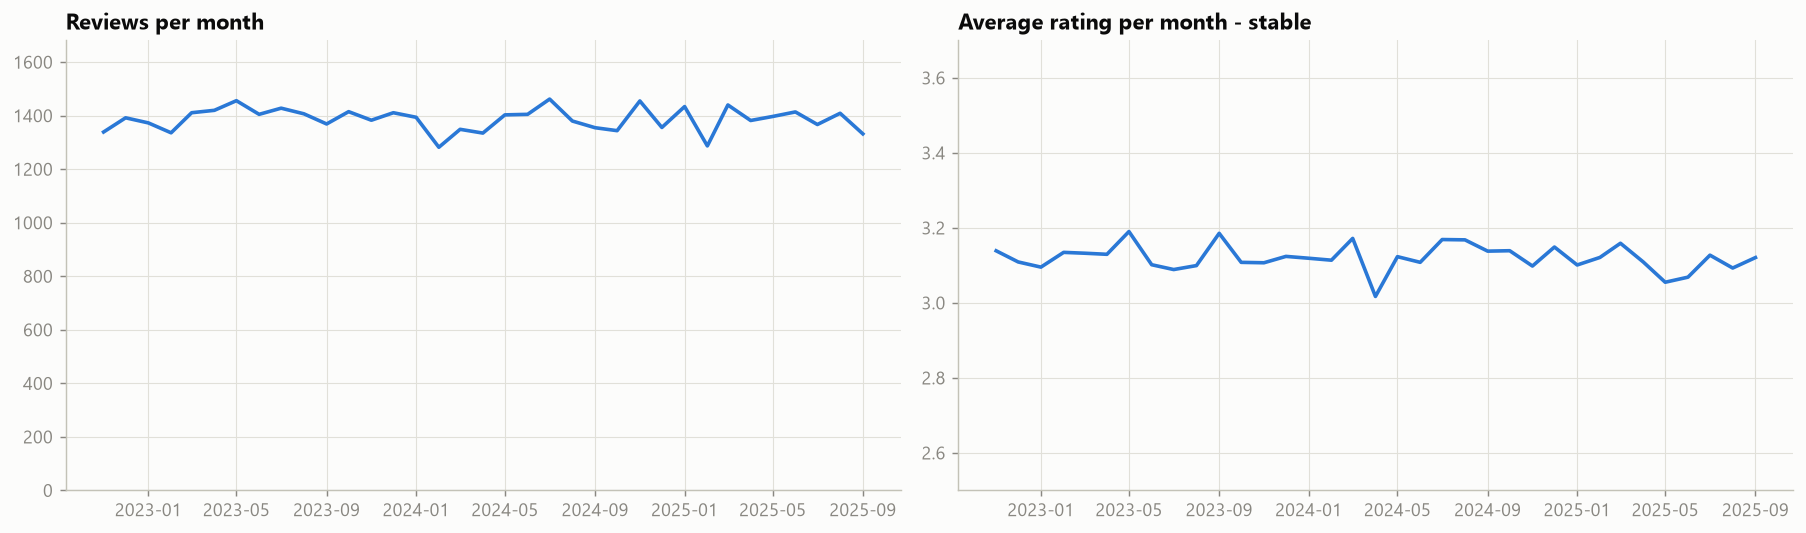

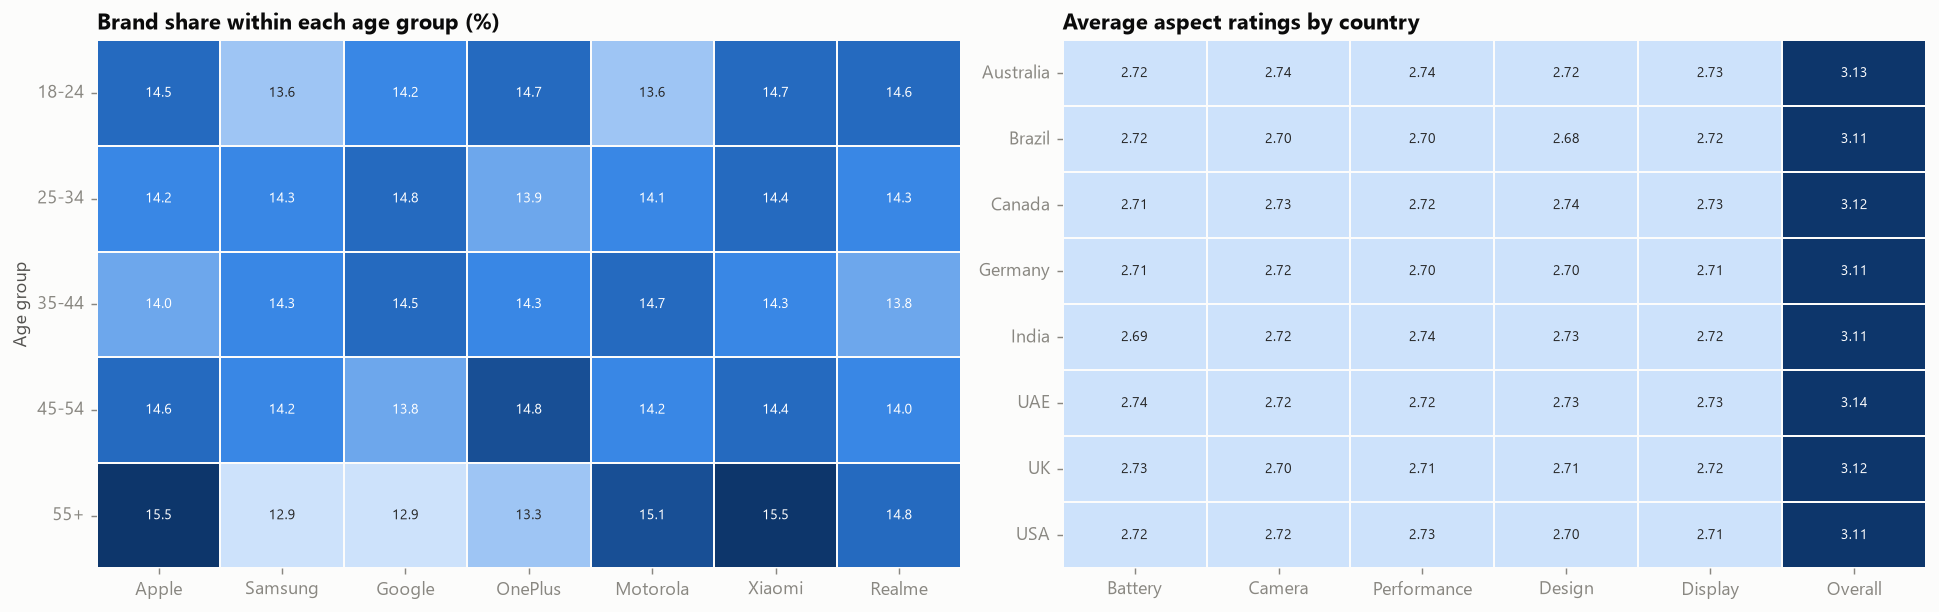

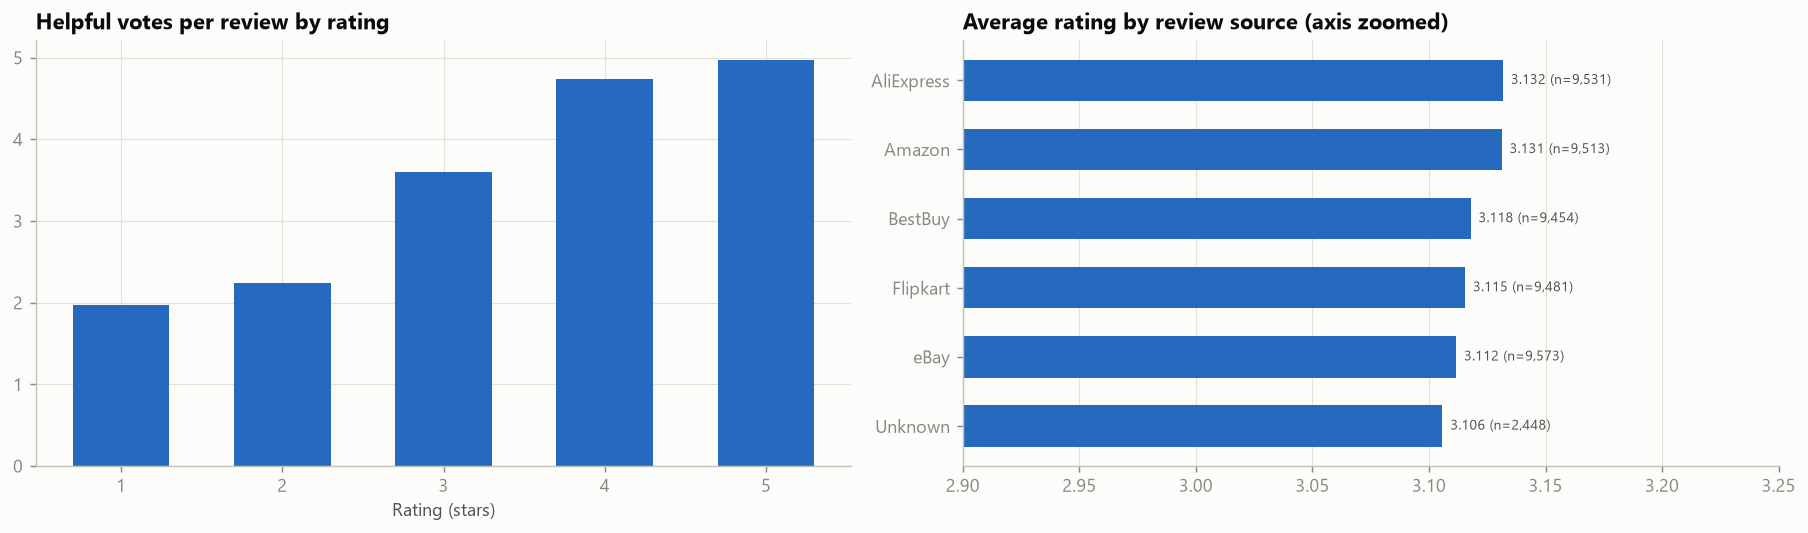

In [16]:
show('eda_07_monthly_trend.png'); show('eda_08_customer_preferences.png'); show('eda_09_engagement_source.png')

### Statistical tests (α = 0.05)

In [17]:
pd.DataFrame(tables['tests']).T

,F,p,significant,H,chi2,dof,r,rho,t
anova_rating_by_brand,0.502848,0.806695,False,NaN,NaN,NaN,NaN,NaN,NaN
kruskal_rating_by_brand,NaN,0.70543,False,3.787331,NaN,NaN,NaN,NaN,NaN
anova_rating_by_model,0.754414,0.778396,False,NaN,NaN,NaN,NaN,NaN,NaN
anova_price_by_brand,12801.113914,0.0,True,NaN,NaN,NaN,NaN,NaN,NaN
chi2_sentiment_vs_brand,NaN,0.331744,False,NaN,13.529673,12.0,NaN,NaN,NaN
chi2_sentiment_vs_country,NaN,0.366362,False,NaN,15.174044,14.0,NaN,NaN,NaN
chi2_sentiment_vs_source,NaN,0.72233,False,NaN,7.032961,10.0,NaN,NaN,NaN
chi2_brand_vs_age_group,NaN,0.522799,False,NaN,22.949192,24.0,NaN,NaN,NaN
chi2_brand_vs_country,NaN,0.832042,False,NaN,33.203088,42.0,NaN,NaN,NaN
pearson_price_vs_rating,NaN,0.738391,False,NaN,NaN,NaN,0.001494,NaN,NaN


## 5. Clustering - customer (review) level
K-Means on standardised **price paid, overall rating and aspect average**. k chosen with elbow, silhouette, Davies-Bouldin and Calinski-Harabasz for k = 2..10.

In [18]:
pd.read_csv(C.REPORTS_DIR / 'customer_k_selection.csv', index_col=0).round(3)

,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,79363.706,0.403,0.969,44499.855
3,58575.911,0.376,0.965,39017.692
4,44490.992,0.348,1.023,39521.492
5,34109.043,0.358,0.888,42466.922
6,29600.870,0.345,0.929,40669.495
7,26003.314,0.346,0.977,39732.017
8,23487.286,0.345,0.914,38468.691
9,21006.773,0.337,0.949,38372.124
10,18912.560,0.341,0.933,38499.527


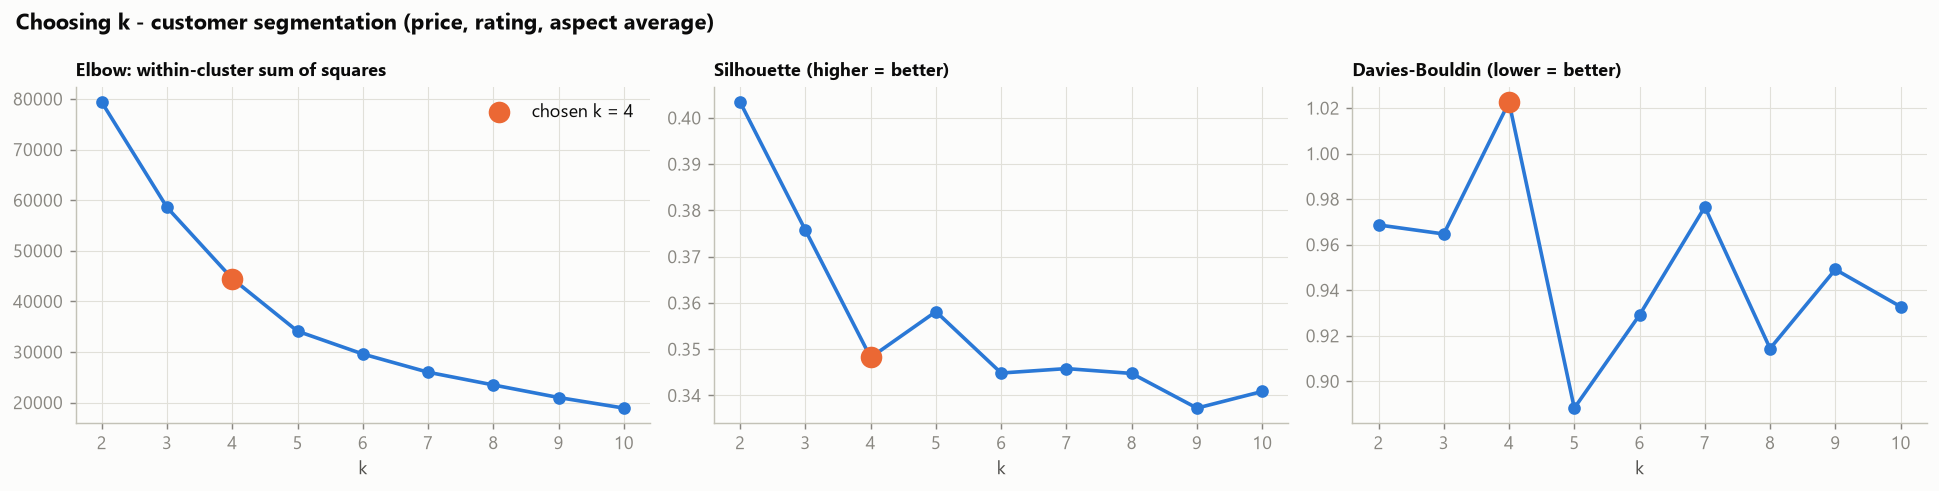

In [19]:
show('seg_01_k_selection_customer.png')

In [20]:
pipe, labels, names, centers, metrics = segmentation.fit_customer_segments(feat)
feat['customer_segment'] = labels
print(metrics)
centers

{'silhouette_sample10k': 0.3482046661910309, 'davies_bouldin': 1.0225892777309131, 'calinski_harabasz': 39521.4925172801, 'inertia': 44490.99224921317}


,price_usd,rating,aspect_avg
Budget/Mid · Satisfied,491.765,4.206,3.705
Budget/Mid · Dissatisfied,496.803,2.141,1.829
Premium · Dissatisfied,1037.535,2.137,1.820
Premium · Satisfied,1028.385,4.208,3.707


In [21]:
segmentation.customer_segment_profile(feat)

,reviews,share_%,avg_price_usd,avg_rating,avg_aspect,positive_%,negative_%,avg_helpful_votes,verified_%,avg_age,top_brand,top_model,Battery,Camera,Performance,Design,Display
customer_segment,,,,,,,,,,,,,,,,,
Premium · Satisfied,8750,17.50,1028.85,4.21,3.71,89.73,0.94,4.69,80.43,30.15,Apple,iPhone 13,3.72,3.71,3.70,3.70,3.71
Premium · Dissatisfied,9384,18.77,1036.82,2.14,1.82,24.95,36.26,2.71,80.41,30.09,Apple,iPhone SE,1.82,1.82,1.82,1.82,1.82
Budget/Mid · Satisfied,14982,29.96,492.03,4.21,3.71,90.17,1.03,4.69,79.95,30.18,Realme,Realme Narzo 70,3.71,3.70,3.71,3.69,3.71
Budget/Mid · Dissatisfied,16884,33.77,496.40,2.14,1.83,24.64,35.92,2.69,80.00,29.93,Xiaomi,Realme Narzo 70,1.82,1.82,1.83,1.83,1.83


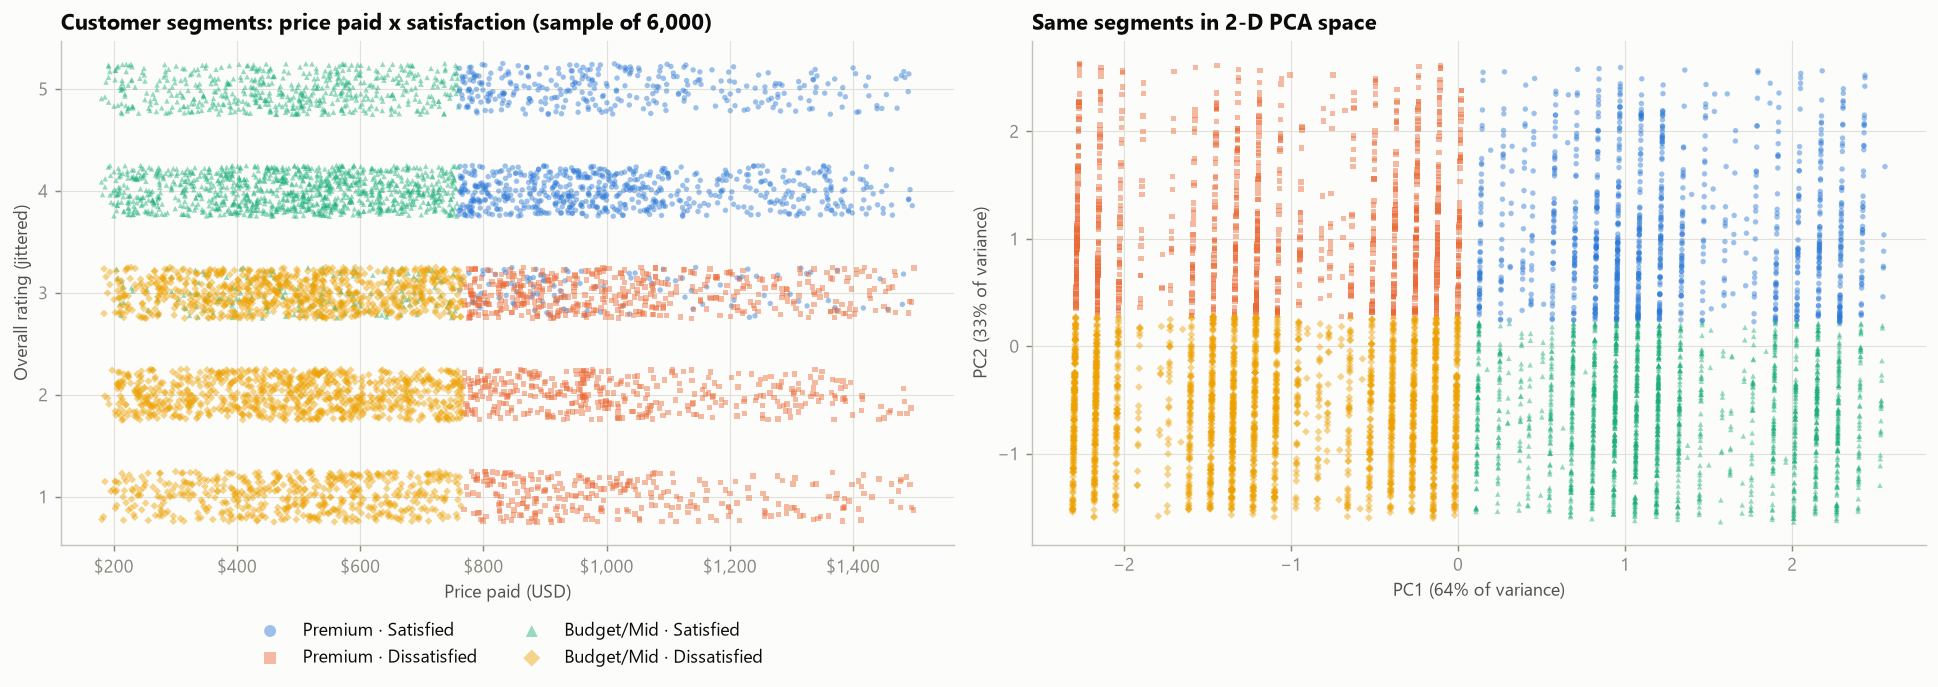

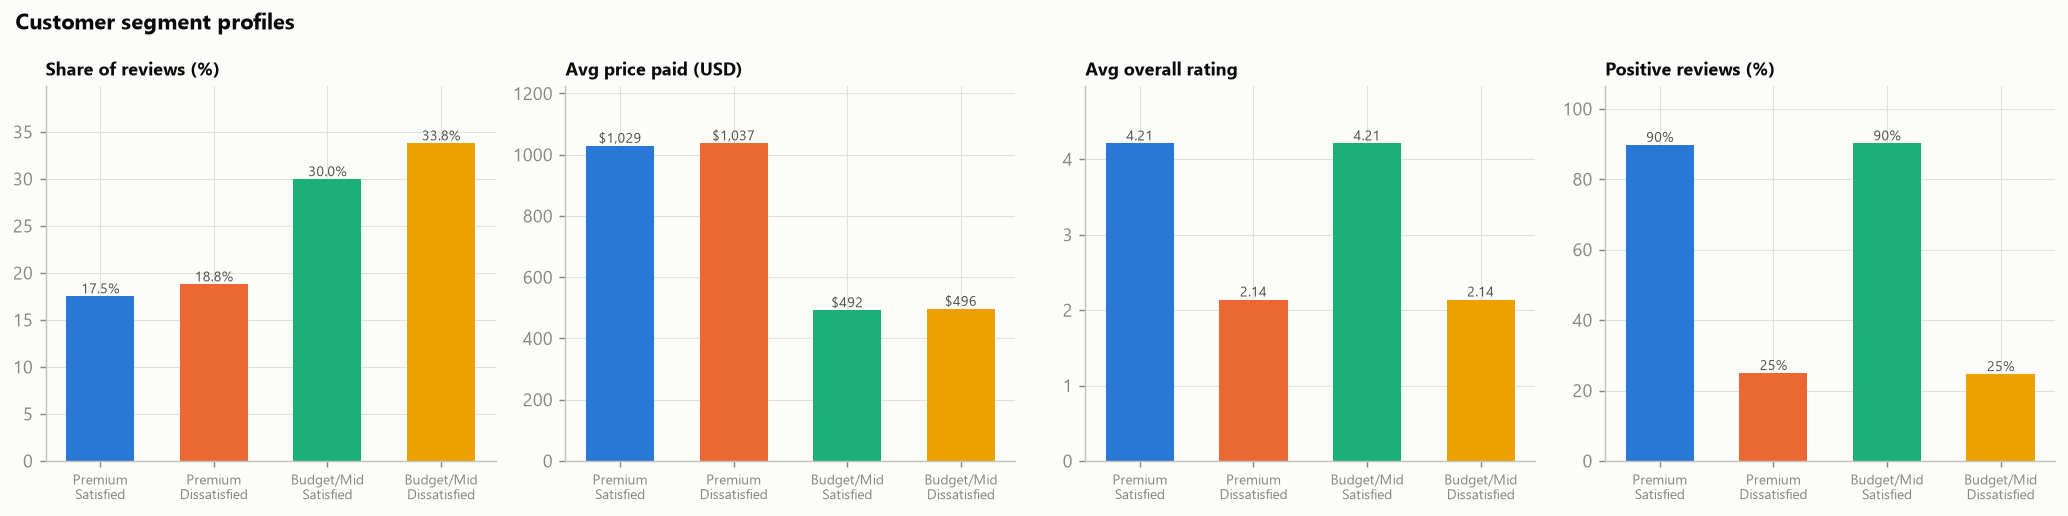

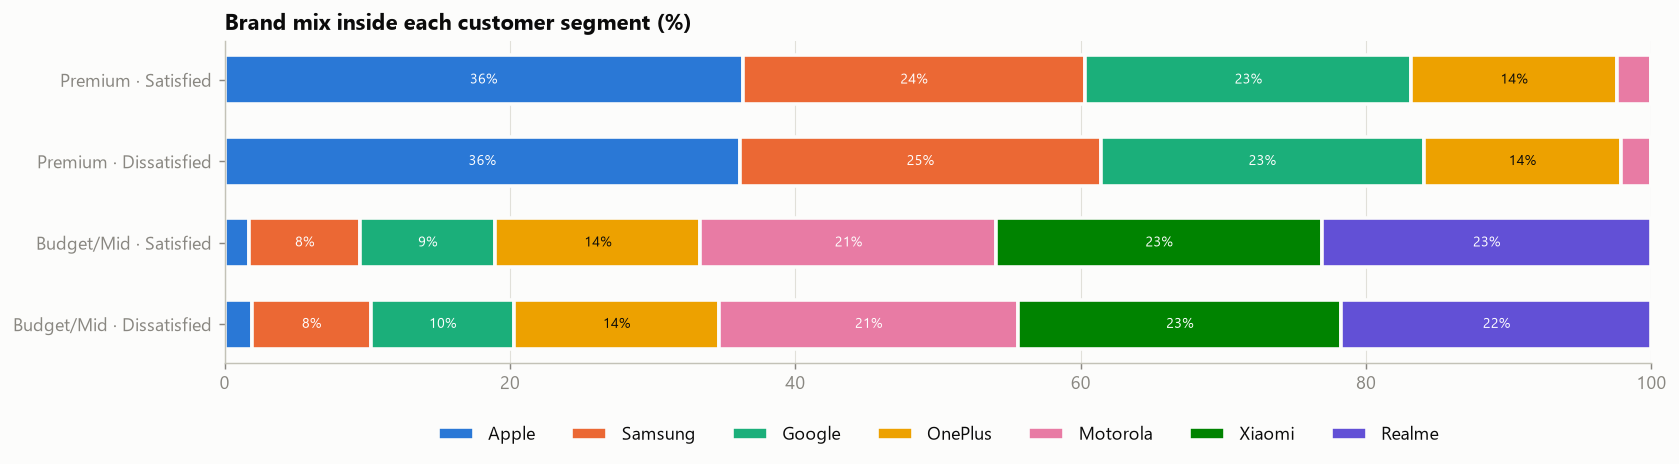

In [22]:
show('seg_03_customer_clusters.png'); show('seg_04_customer_segment_profiles.png'); show('seg_06_segment_brand_mix.png')

Feature-selection check - adding one-hot brand and country (plus age and engagement) to the clustering:

In [23]:
segmentation.alternative_encoded_clustering(feat)

{'features': ['price_usd',
  'rating',
  'aspect_avg',
  'age',
  'engagement_score',
  'brand (one-hot)',
  'country (one-hot)'],
 'silhouette_sample10k': 0.13506253480863514,
 'davies_bouldin': 2.1669652397952746,
 'cluster_rating_spread': 2.146672331074395,
 'cluster_price_spread': 574.8160865407942}

## 6. Clustering - product (model) level
Rating features hardly vary across the 22 models (coefficient of variation < 2.1%), so product segments are formed on price structure.

In [24]:
segmentation.product_feature_variation(products)

,mean,std,cv_%
avg_price_usd,731.7668,249.9603,34.1585
avg_rating,3.1199,0.0243,0.7777
positive_share,0.5569,0.0113,2.0310
avg_aspect,2.7171,0.0228,0.8388
avg_engagement,5.1012,0.0708,1.3872
avg_age,30.0871,0.2030,0.6748


In [25]:
ppipe, plabels, pnames, pmetrics = segmentation.fit_product_segments(products)
products['product_segment'] = plabels
feat['product_segment'] = feat.model.map(products.set_index('model').product_segment)
print(pmetrics)
segmentation.product_segment_profile(products)

{'silhouette': 0.7907258763119174, 'davies_bouldin': 0.35838178812861576, 'calinski_harabasz': 163.3499814310864}


,models,brands,reviews,avg_price_usd,price_range_usd,avg_rating,positive_%,value_score
product_segment,,,,,,,,
Budget,8,"Motorola, Realme, Xiaomi",21434,456.878,$188 - $790,3.117,55.475,0.780
Mid-range,6,"Google, OnePlus",14370,738.629,"$361 - $1,090",3.124,55.952,0.457
Upper mid-range,4,Samsung,7052,899.448,"$420 - $1,382",3.111,55.448,0.389
Premium,4,Apple,7144,1103.569,"$715 - $1,486",3.127,55.970,0.297


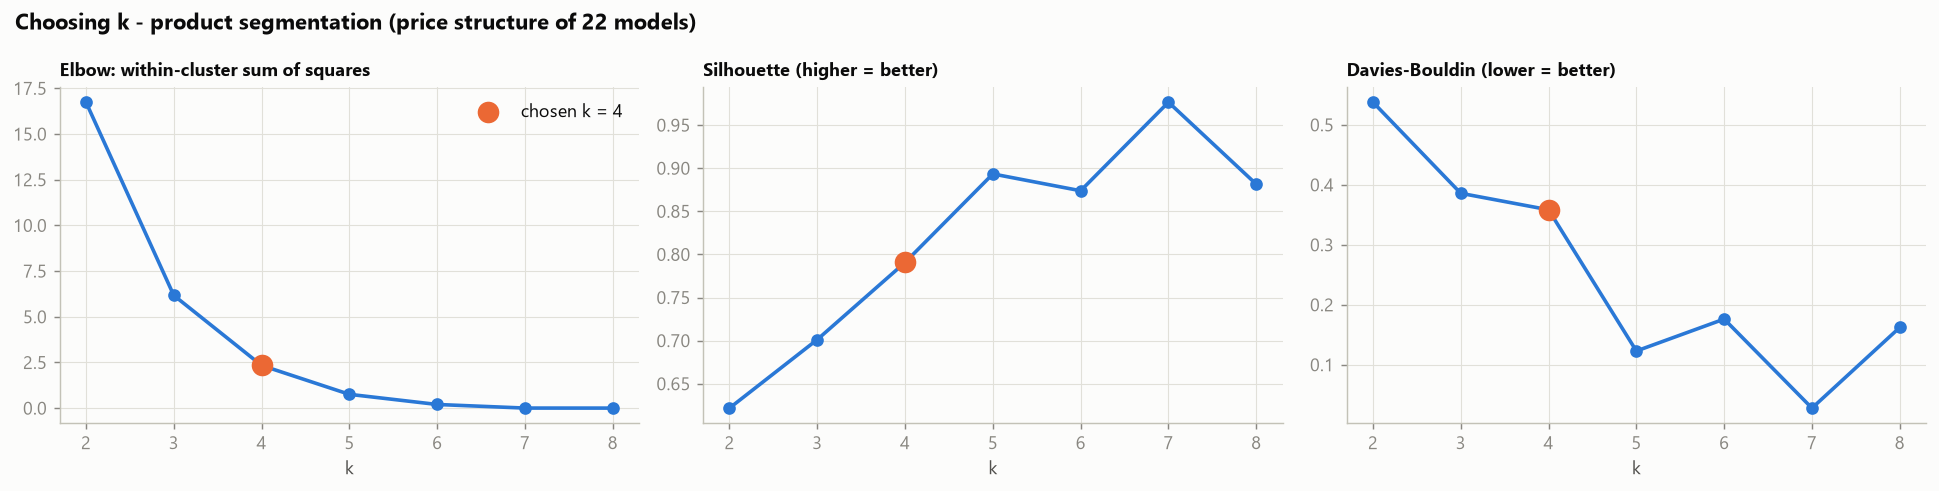

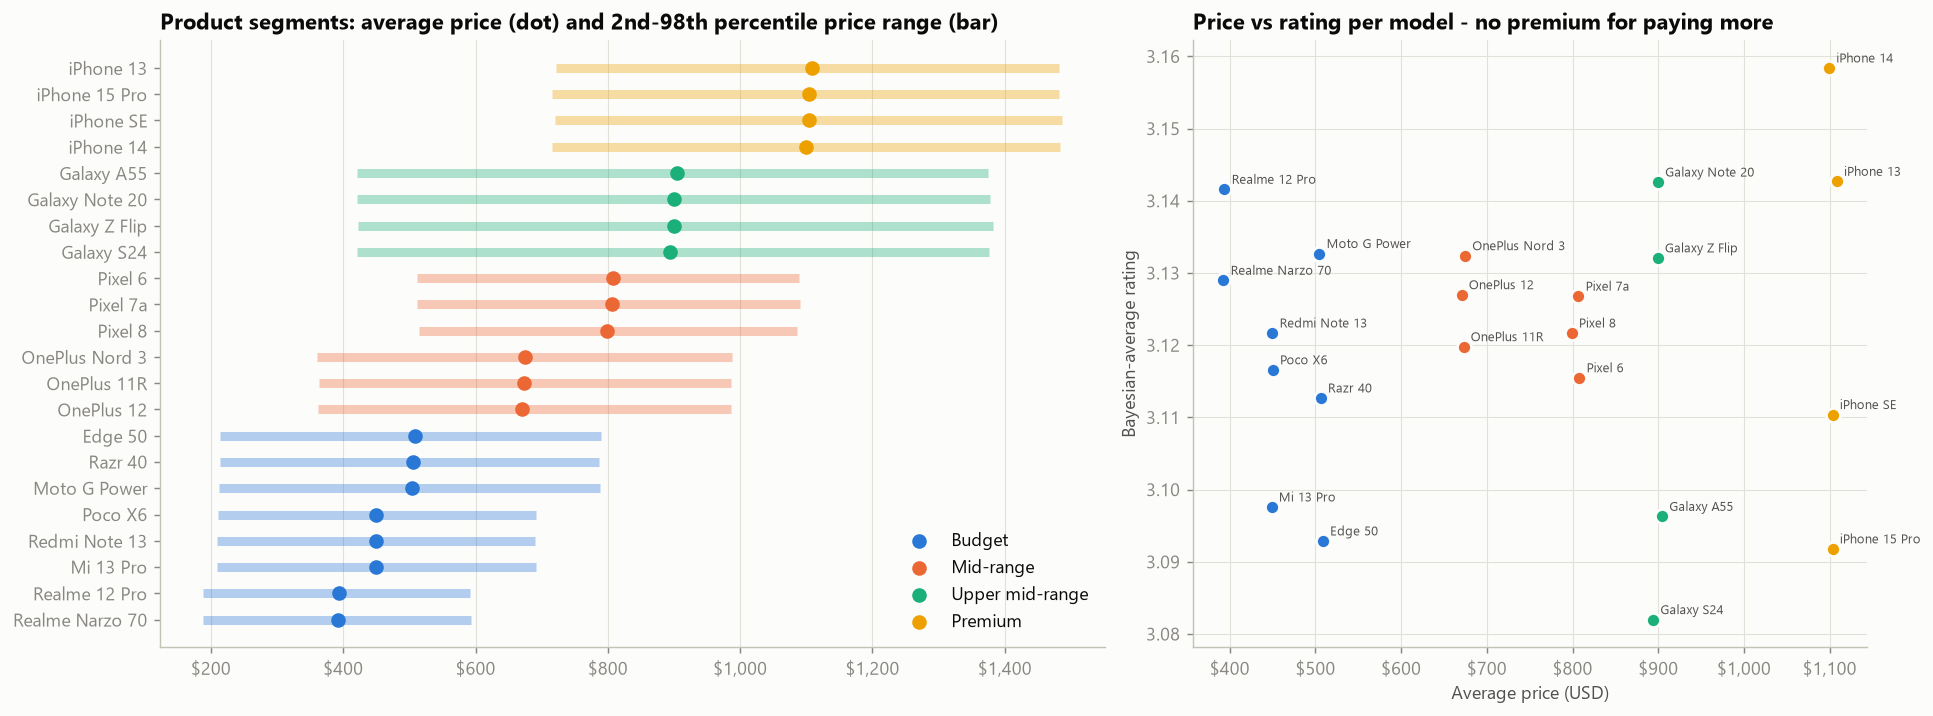

In [26]:
show('seg_02_k_selection_product.png'); show('seg_05_product_segments.png')

## 7. Recommendation system
* **Content-based**: product vectors → cosine similarity or Euclidean-distance similarity
* **Preference-based (hybrid)**: budget + aspect priorities + country / age group
* **Collaborative filtering basics**: item-item adjusted cosine on a customer-group × phone matrix

In [27]:
rec = recommender.ProductRecommender(products, feat)
rec.recommend_similar('iPhone 14', 5)[['model','brand','product_segment','avg_price_usd','avg_rating','similarity','reason']]

,model,brand,product_segment,avg_price_usd,avg_rating,similarity,reason
0,iPhone 13,Apple,Premium,1108.2654,3.1488,0.928558,same Premium segment · avg price +$9 · stronge...
1,iPhone SE,Apple,Premium,1103.3810,3.1075,0.892114,same Premium segment · avg price +$4 · stronge...
2,iPhone 15 Pro,Apple,Premium,1103.4099,3.0837,0.859338,same Premium segment · avg price +$4 · stronge...
3,Galaxy Z Flip,Samsung,Upper mid-range,899.3834,3.1354,0.361264,avg price -$200 · strongest aspect: Performance
4,Galaxy A55,Samsung,Upper mid-range,904.5384,3.0895,0.359753,avg price -$195 · strongest aspect: Battery


In [28]:
rec.recommend_similar('Realme 12 Pro', 5, metric='cosine')[['model','product_segment','avg_price_usd','similarity']]

,model,product_segment,avg_price_usd,similarity
0,Realme Narzo 70,Budget,392.7068,0.999805
1,Redmi Note 13,Budget,449.7820,0.998198
2,Poco X6,Budget,450.2666,0.997993
3,Mi 13 Pro,Budget,448.9141,0.997087
4,OnePlus 11R,Mid-range,672.7866,0.996583


In [29]:
rec.recommend_for_user(budget_min=150, budget_max=450, priorities={'battery_life_rating': 3, 'performance_rating': 2}, country='India', age_group='18-24')

,model,brand,product_segment,typical_price_in_budget_usd,budget_fit,aspect_match,cf_predicted_rating,positive_share,peer_reviews,score
0,Realme 12 Pro,Realme,Budget,318.560,0.635926,2.830645,3.178352,0.5717,124,0.588157
1,Realme Narzo 70,Realme,Budget,318.045,0.633306,2.752518,3.167098,0.5566,139,0.576575
2,Redmi Note 13,Xiaomi,Budget,324.270,0.496761,2.861176,3.032224,0.5652,85,0.559154
3,Mi 13 Pro,Xiaomi,Budget,332.660,0.514928,2.728736,3.119653,0.5562,87,0.549492
4,Poco X6,Xiaomi,Budget,324.760,0.494411,2.591011,3.023429,0.5426,89,0.526972


In [30]:
rec.similar_by_ratings('Pixel 8')

,model,brand,product_segment,avg_price_usd,avg_rating,cf_similarity
0,Galaxy Z Flip,Samsung,Upper mid-range,899.3834,3.1354,0.455
1,Edge 50,Motorola,Budget,508.6976,3.0868,0.401
2,Moto G Power,Motorola,Budget,504.6061,3.1353,0.336
3,Galaxy Note 20,Samsung,Upper mid-range,899.7462,3.1487,0.205
4,Poco X6,Xiaomi,Budget,450.2666,3.1156,0.158


### Validating recommendation relevance

In [31]:
recommender.evaluate_content(rec)

,same_segment@3_%,mean_abs_price_diff_usd,mean_abs_rating_diff,other_brand_share_%,catalog_coverage_%
metric,,,,,
euclidean,100.000,23.187,0.028,24.242,100.000
cosine,80.303,57.233,0.029,31.818,95.455
random,24.242,274.089,0.026,89.394,86.364


In [32]:
recommender.evaluate_cf(feat, products)

{'rmse_global': 0.3393,
 'mae_global': 0.2556,
 'rmse_item': 0.3423,
 'mae_item': 0.2561,
 'rmse_group': 0.3419,
 'mae_group': 0.2564,
 'rmse_cf': 0.3548,
 'mae_cf': 0.2628,
 'precision@3_cf': 0.1042,
 'precision@3_random_expected': 0.1364,
 'groups': 40,
 'test_cells': 745}

In [33]:
recommender.evaluate_personas(rec)

,persona,budget_usd,priorities,top_recommendations,in_budget_%,avg_priority_score_recs,catalog_priority_score
0,Student on a budget,150-450,"Battery, Performance","Realme 12 Pro, Realme Narzo 70, Redmi Note 13",100.0,2.753,2.719
1,Camera-first creator,600-1100,"Camera, Display","Pixel 8, Pixel 6, Pixel 7a",100.0,2.808,2.719
2,Premium professional,1000-1600,"Performance, Design","iPhone 13, iPhone 14, iPhone 15 Pro",100.0,2.783,2.717
3,Mid-range all-rounder,400-800,"Battery, Camera, Performance, Design, Display","Moto G Power, Edge 50, Razr 40",100.0,2.712,2.718


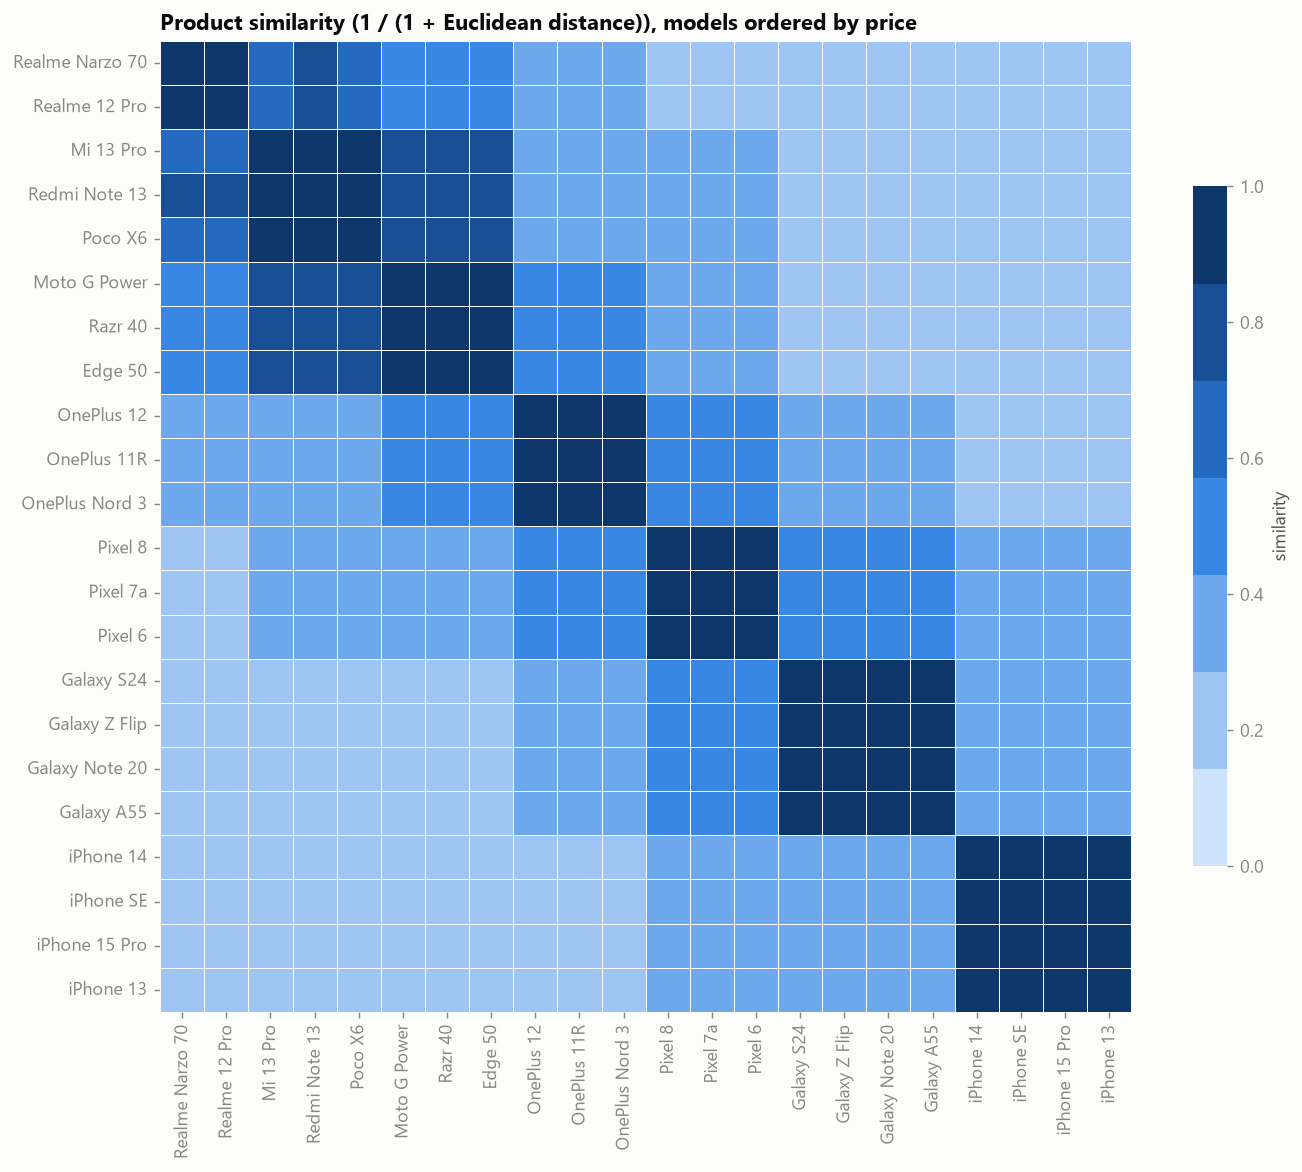

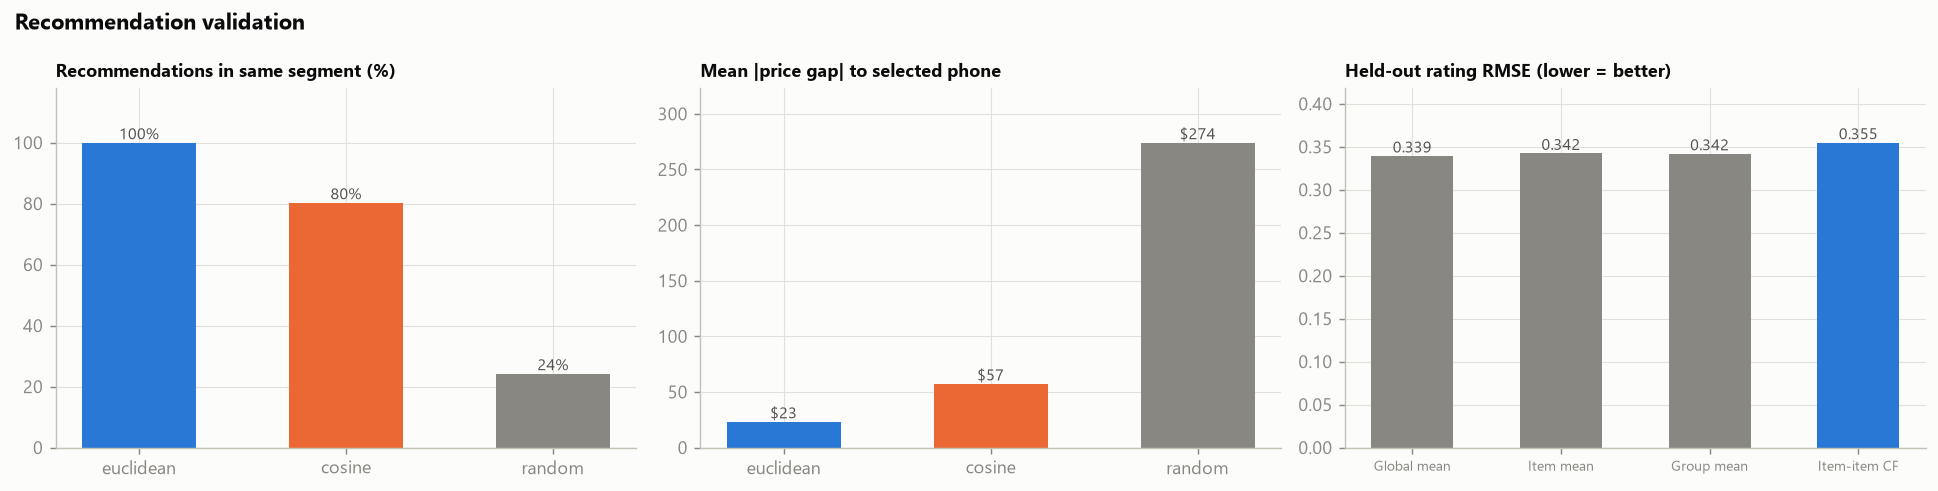

In [34]:
show('rec_01_similarity_heatmap.png'); show('rec_02_recommender_evaluation.png')

## 8. Using the saved models

In [35]:
km = joblib.load(C.MODELS_DIR / 'kmeans_customer_segments.joblib')
meta = json.loads((C.MODELS_DIR / 'model_metadata.json').read_text())
new = pd.DataFrame([{'price_usd': 1150, 'rating': 2, 'aspect_avg': 1.8},
                    {'price_usd': 350, 'rating': 5, 'aspect_avg': 4.2}])
[meta['customer_segmentation']['cluster_names'][str(i)] for i in km.predict(new)]

['Premium · Dissatisfied', 'Budget/Mid · Satisfied']

See `reports/EDA_Report.md`, `reports/Cluster_Analysis_Report.md` and `reports/Recommendation_System_Report.md` for insights and recommendations.